Dataset shape: (1000, 21)
Features: (1000, 20)
Target: (1000,)
                          Type  Missing  Unique
checking_account           str        0       4
duration                 int64        0      33
credit_history             str        0       5
purpose                    str        0      10
credit_amount            int64        0     921
savings_account            str        0       5
employment                 str        0       5
installment_rate         int64        0       4
personal_status            str        0       4
other_debtors              str        0       3
residence_since          int64        0       4
property                   str        0       4
age                      int64        0      53
other_installment_plans    str        0       3
housing                    str        0       3
existing_credits         int64        0       4
job                        str        0       4
dependents               int64        0       2
telephone                

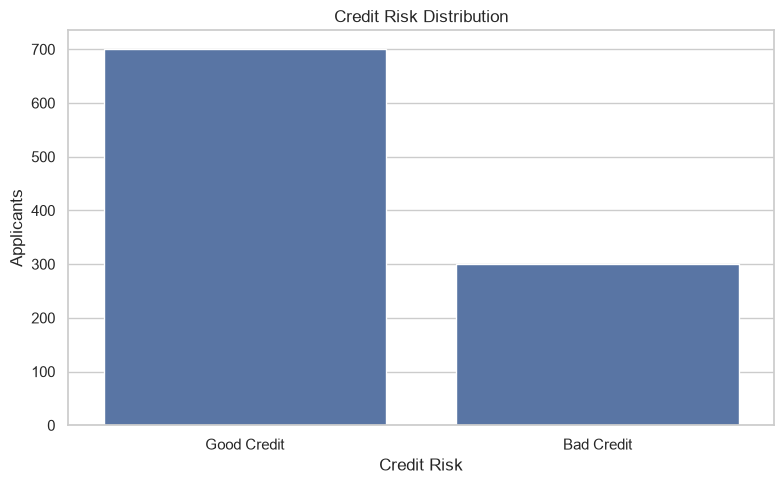

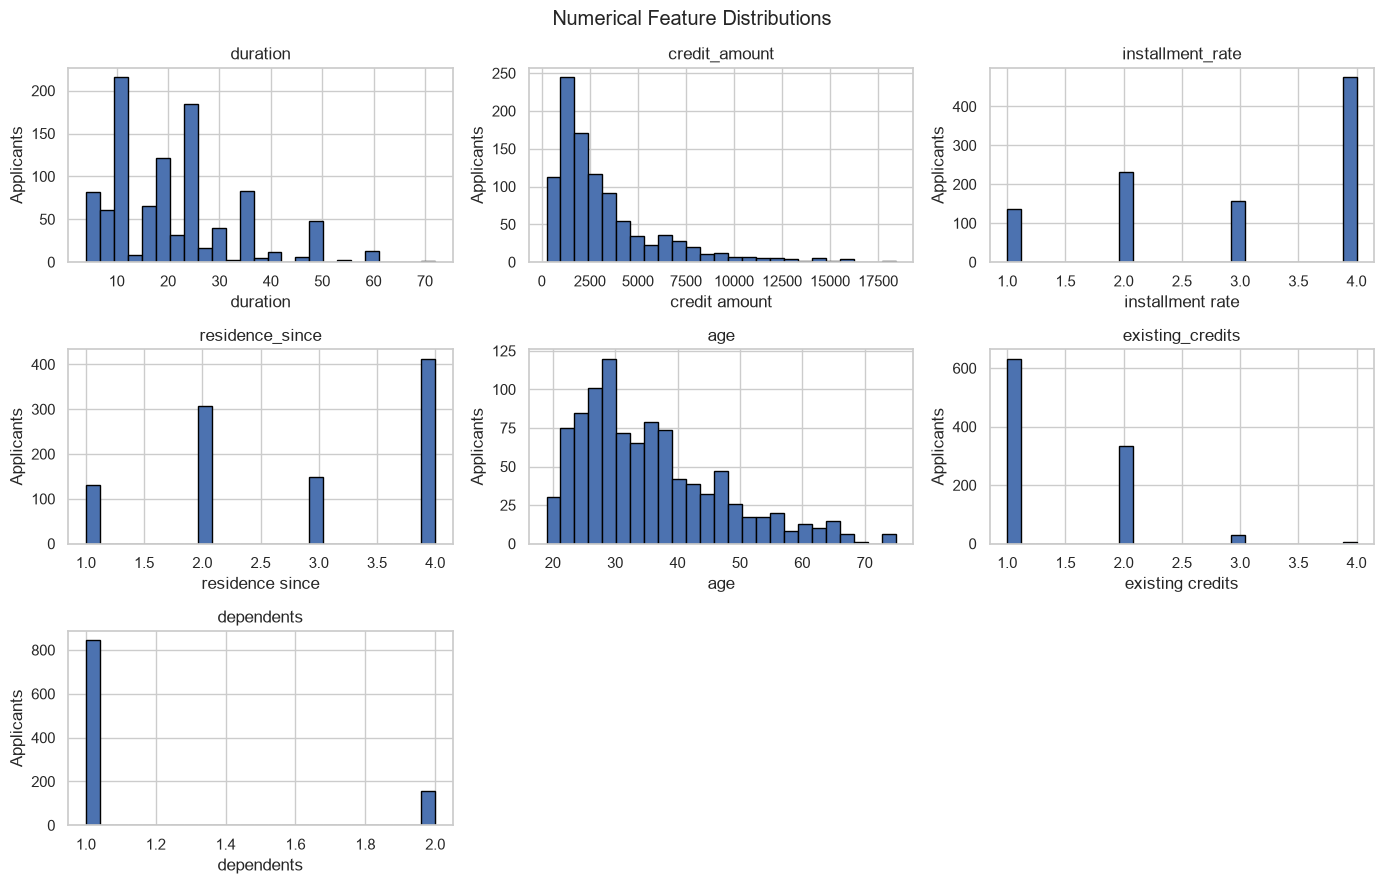

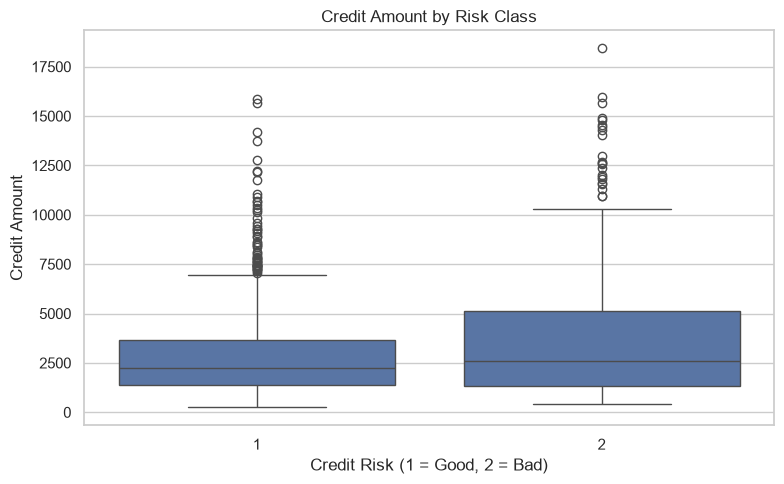

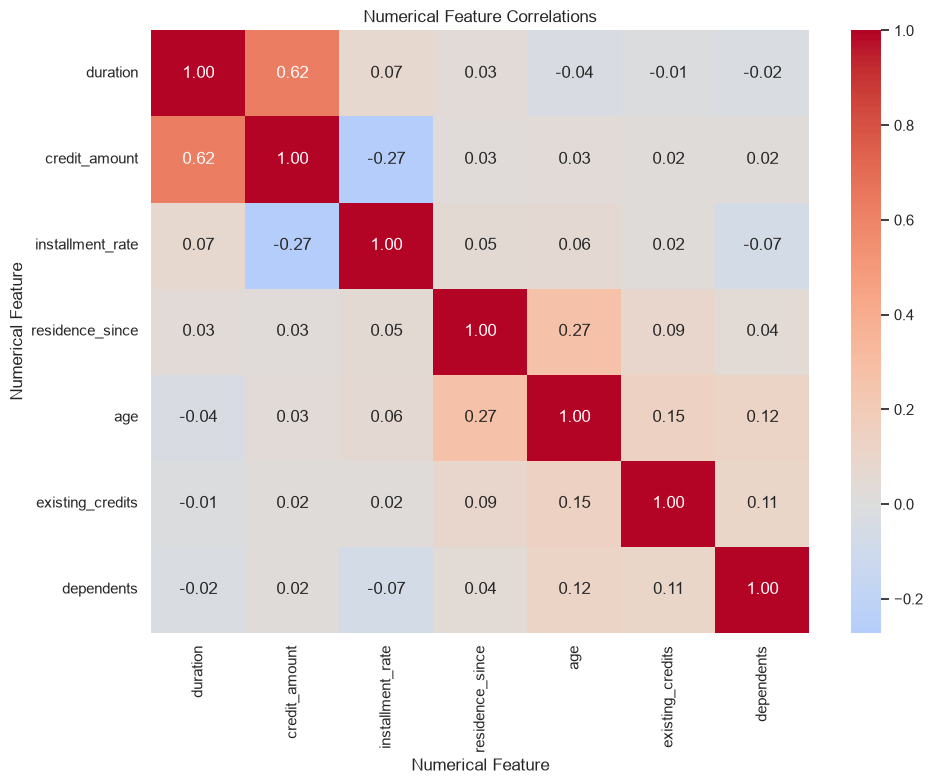

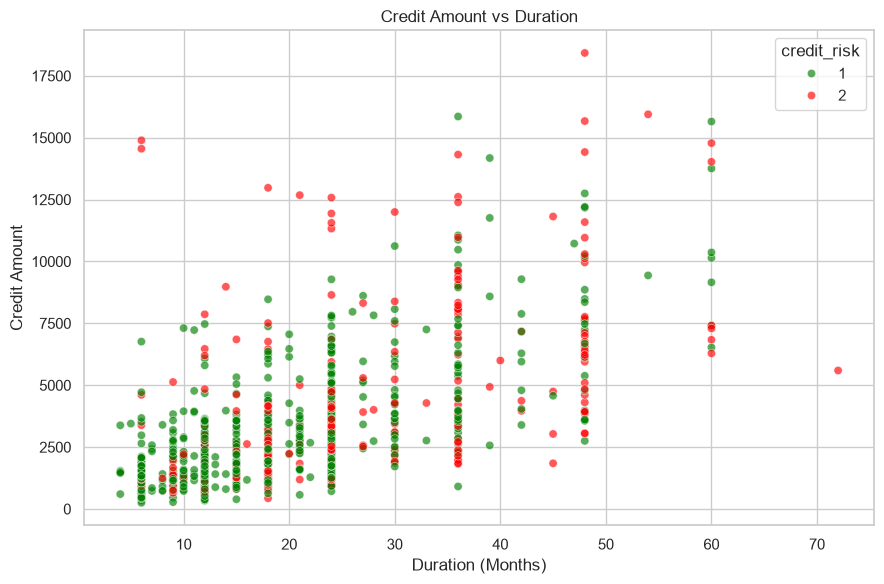

Training samples: 800
Testing samples: 200
Features before: 20
Features after: 61


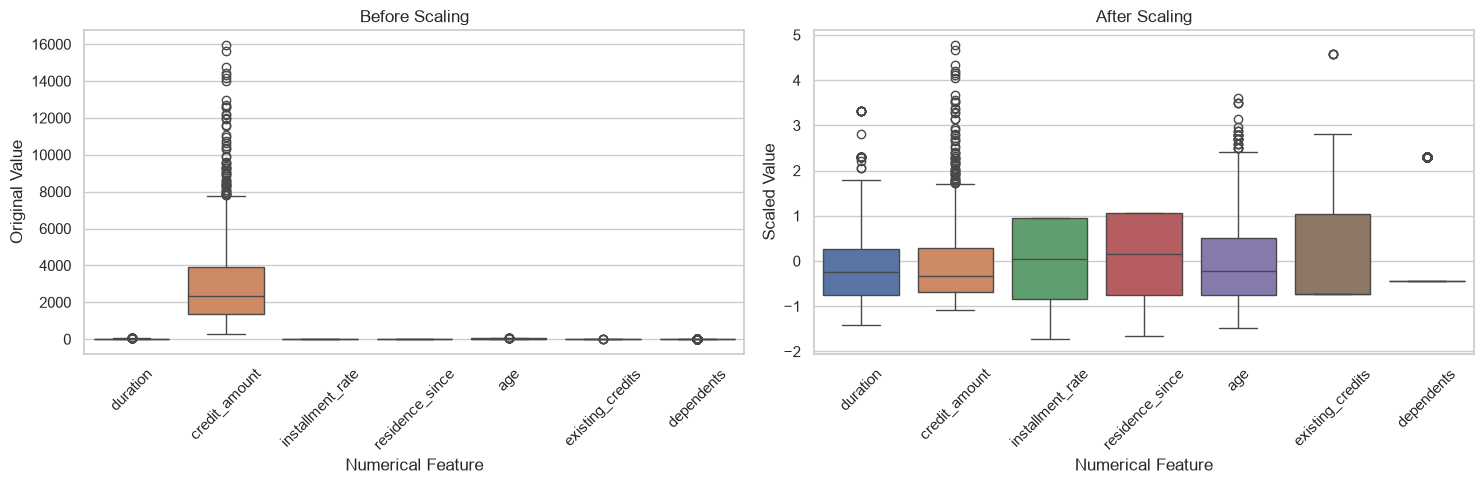

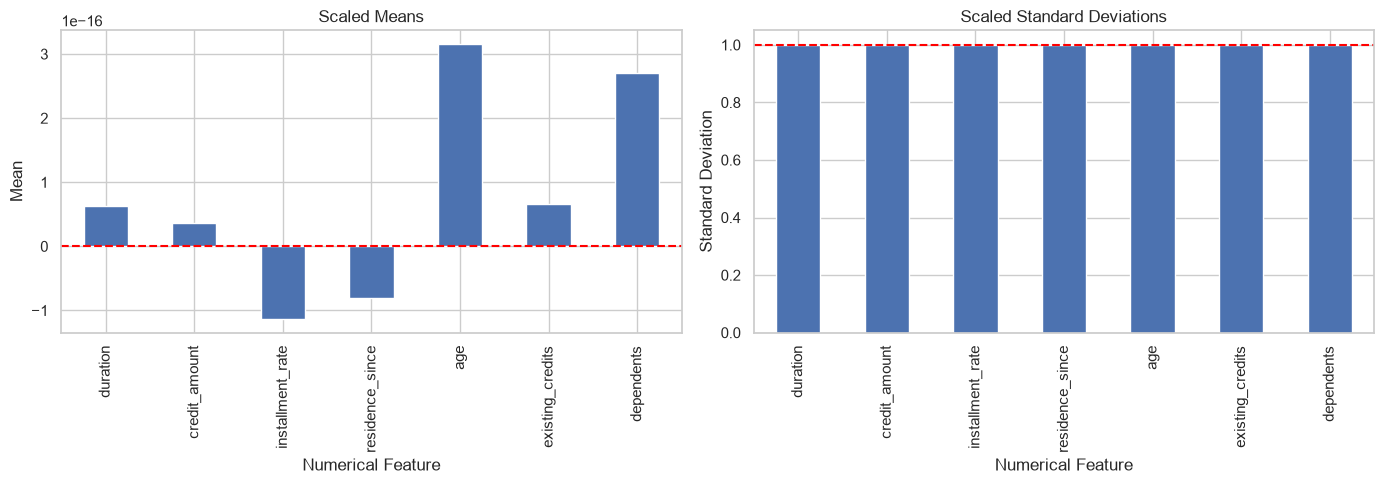

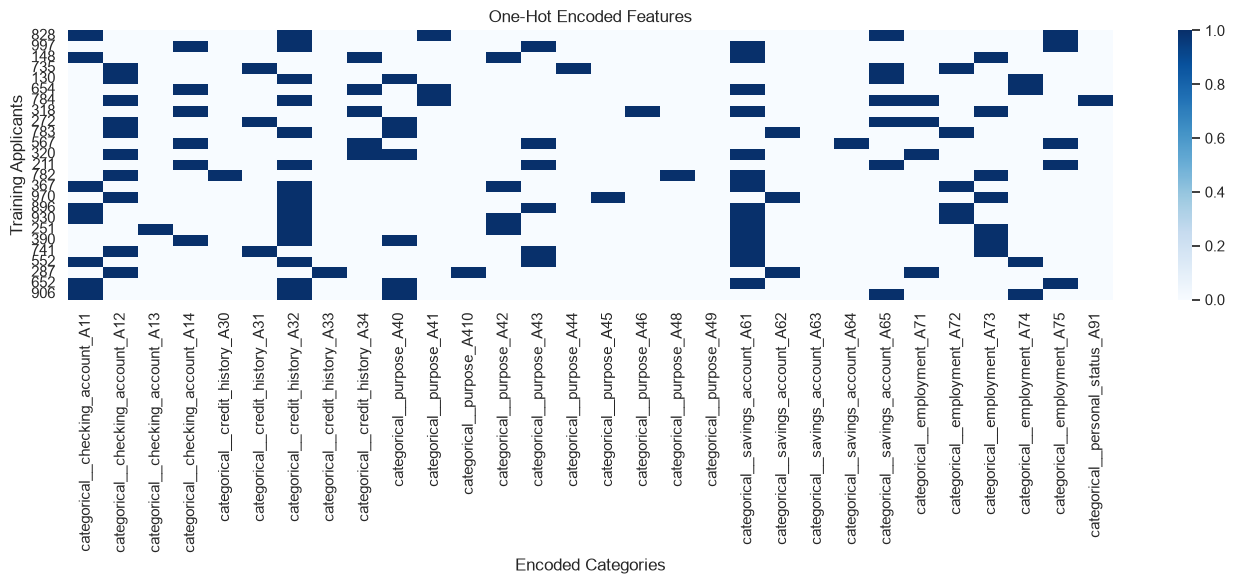

Only 0 and 1: True
Missing values: 0
Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV F1-score: 0.4572

Best configurations by F1:
    k   weights   distance  mean_test_bad_f1  mean_test_accuracy  \
5   5  distance  Manhattan             0.457               0.745   
4   5   uniform  Manhattan             0.455               0.746   
9   7  distance  Manhattan             0.440               0.753   
13  9  distance  Manhattan             0.439               0.754   
7   5  distance  Euclidean             0.434               0.744   
6   5   uniform  Euclidean             0.430               0.742   
0   3   uniform  Manhattan             0.429               0.736   
3   3  distance  Euclidean             0.427               0.726   
1   3  distance  Manhattan             0.426               0.732   
2   3   uniform  Euclidean             0.423               0.725   

    mean_test_balanced_accuracy  
5                         0.635  
4          

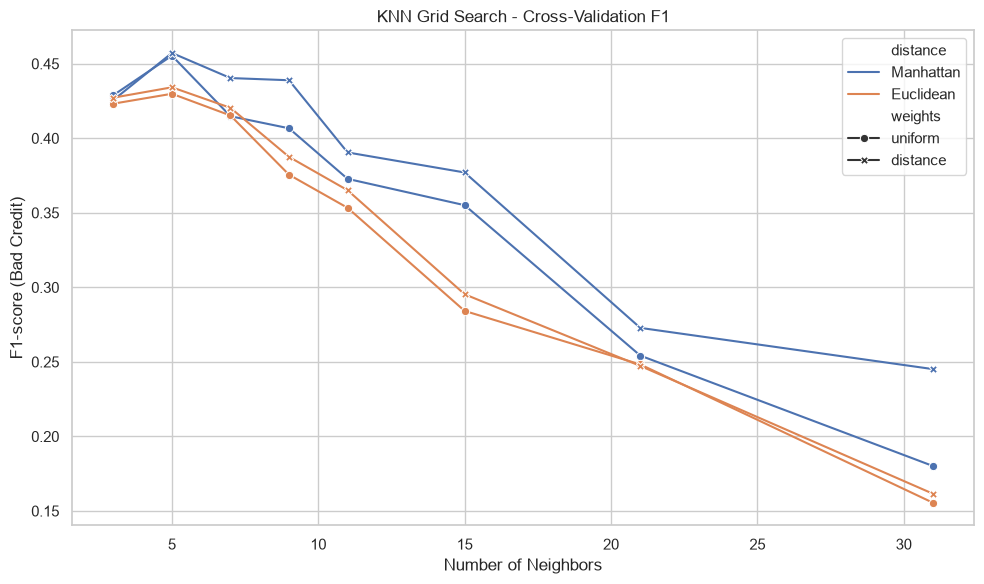

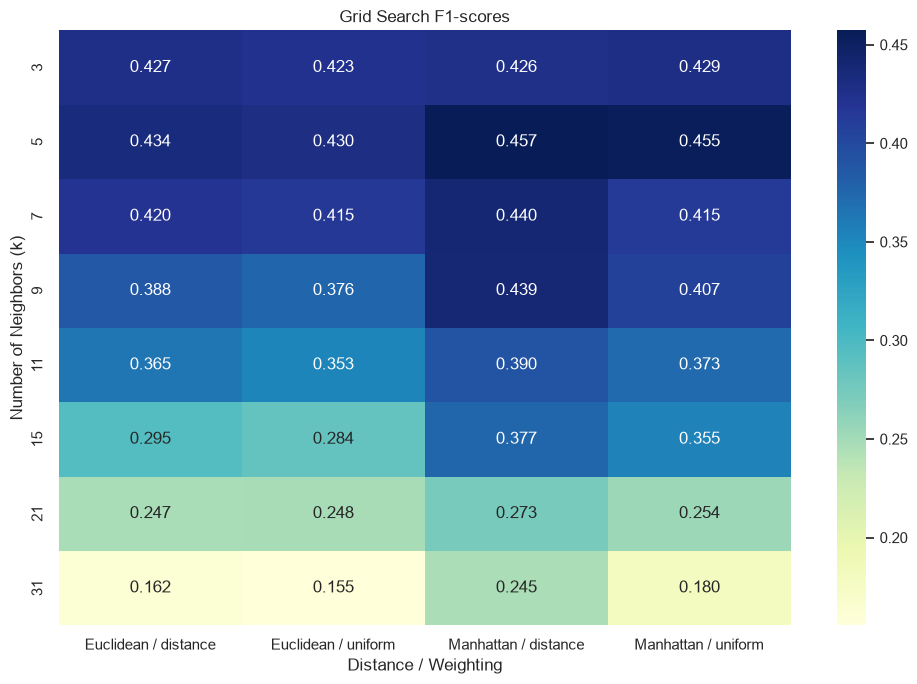

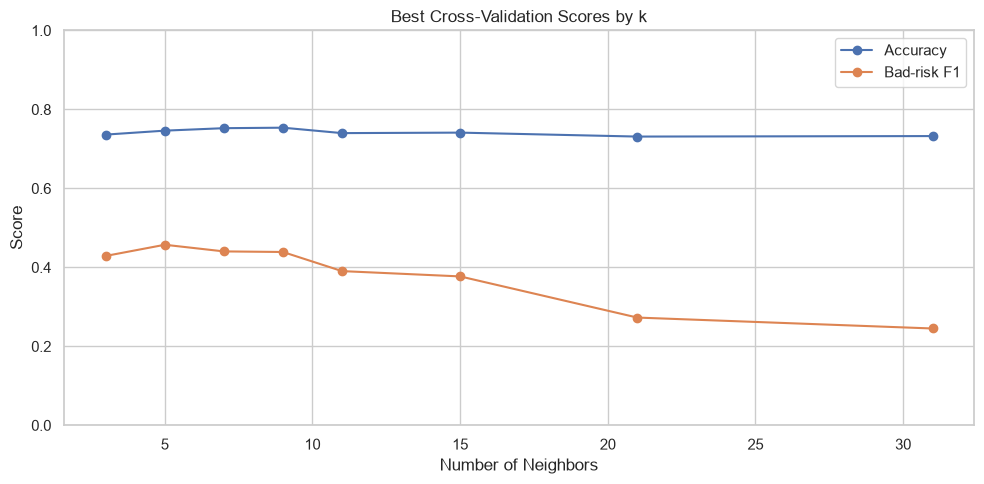


Final test results:
      Metric   Score
0   Accuracy  0.7300
1  Precision  0.5750
2     Recall  0.3833
3         F1  0.4600

Classification report:
              precision    recall  f1-score   support

 Good Credit       0.77      0.88      0.82       140
  Bad Credit       0.57      0.38      0.46        60

    accuracy                           0.73       200
   macro avg       0.67      0.63      0.64       200
weighted avg       0.71      0.73      0.71       200


Majority-class baseline accuracy: 0.7


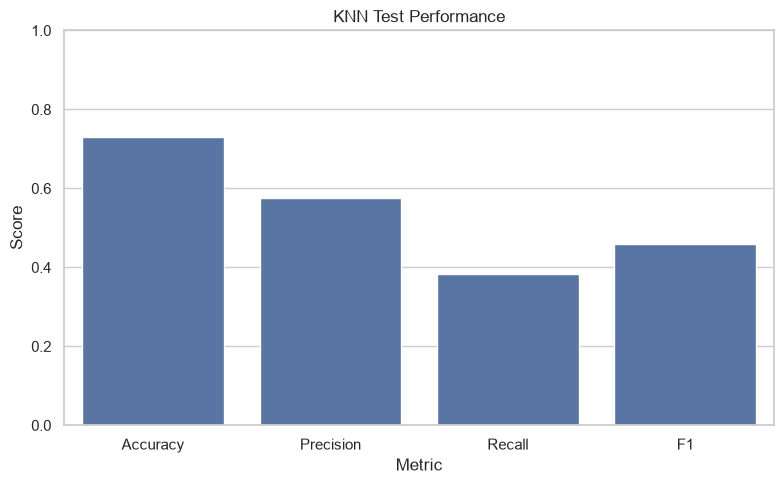

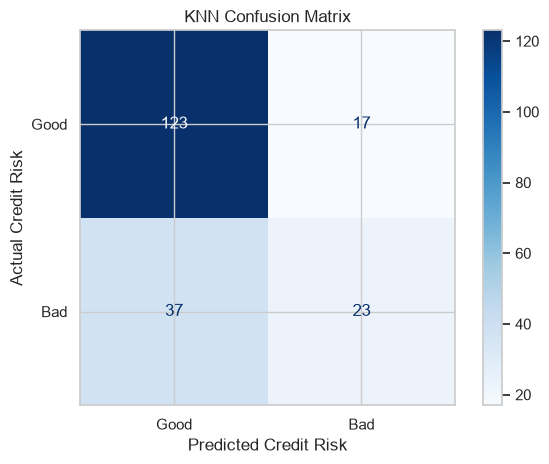

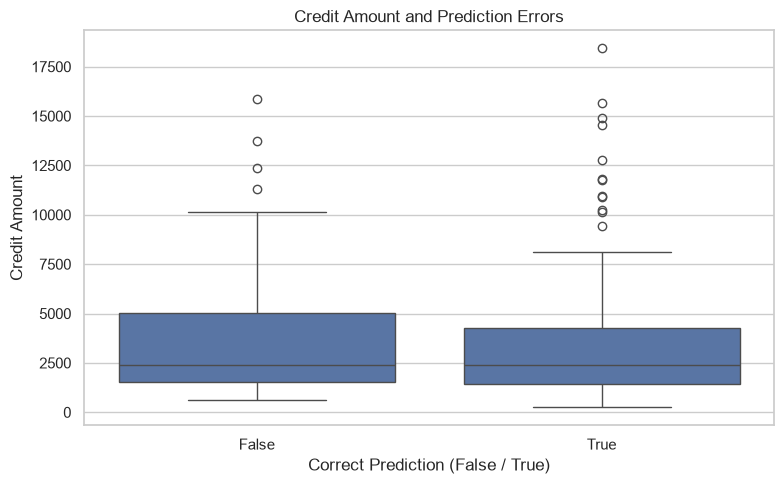


Summary:
Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Test accuracy: 0.73
Test F1 (bad credit): 0.46
Test recall (bad credit): 0.3833
Test precision (bad credit): 0.575


In [ ]:
# Student: Gleb Matyushev
# Student ID: 12552707
# Group: [Your group]
# Dataset: Statlog German Credit
# Algorithm: KNN

# I used F1-score to select the best model because the dataset is imbalanced.
# There are more good credit applicants than bad credit applicants.
# Using accuracy alone could give a good score even if the model
# does not identify many bad credit applicants.

# I used GridSearchCV to find the best number of neighbors,
# distance metric and weighting method.


# ---------------------------------------------------------
# 1. Imports
# ---------------------------------------------------------

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")


# ---------------------------------------------------------
# 2. Load dataset
# ---------------------------------------------------------

data_path = Path.cwd() / "data" / "german.data"

if not data_path.exists():
    data_path = Path.cwd() / "01_German_Credit_KNN" / "data" / "german.data"

if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

column_names = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk",
]

df = pd.read_csv(data_path, sep=r"\s+", header=None, names=column_names)

# X contains the applicant information, y contains the correct credit risk (1 or 2)
X = df.drop(columns="credit_risk")
y = df["credit_risk"]

print("Dataset shape:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)


# ---------------------------------------------------------
# 3. Data inspection
# ---------------------------------------------------------

# Get the numerical and categorical column names separately
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

feature_summary = pd.DataFrame(
    {"Type": X.dtypes.astype(str), "Missing": X.isna().sum(), "Unique": X.nunique()}
)

print(feature_summary)
print("\nMissing values:", X.isna().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("\nTarget distribution:")
print(y.value_counts().sort_index())


# ---------------------------------------------------------
# 4. Exploratory data analysis
# ---------------------------------------------------------

# Credit risk distribution

# 1 = good credit, 2 = bad credit
class_counts = y.value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=["Good Credit", "Bad Credit"], y=class_counts.values)
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Applicants")
plt.tight_layout()
plt.show()


# Numerical feature distributions

hist_axes = X[numeric_features].hist(figsize=(14, 9), bins=25, edgecolor="black")

# Each histogram shows the values of one numerical feature
for ax, feature in zip(hist_axes.flat, numeric_features):
    ax.set_xlabel(feature.replace("_", " "))
    ax.set_ylabel("Applicants")

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()


# Credit amount by risk class

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="credit_risk", y="credit_amount", order=[1, 2])
plt.title("Credit Amount by Risk Class")
plt.xlabel("Credit Risk (1 = Good, 2 = Bad)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# Correlations between numerical features

plt.figure(figsize=(10, 8))
sns.heatmap(
    X[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Numerical Feature Correlations")
plt.xlabel("Numerical Feature")
plt.ylabel("Numerical Feature")
plt.tight_layout()
plt.show()


# Credit amount and duration

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="duration",
    y="credit_amount",
    hue="credit_risk",  # Use different colors for good and bad credit
    palette={1: "green", 2: "red"},
    alpha=0.65,  # Make overlapping points easier to see
)
plt.title("Credit Amount vs Duration")
plt.xlabel("Duration (Months)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 5. Train/test split
# ---------------------------------------------------------

# Split before fitting preprocessing, so the test data stays unseen
# 80% for training, 20% for testing
# random_state=42 makes the split reproducible
# stratify=y keeps the same good/bad ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ---------------------------------------------------------
# 6. Preprocessing
# ---------------------------------------------------------

# Median fills missing numbers, StandardScaler makes them comparable for KNN
numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

# Replace missing categories and convert categories into 0/1 columns
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        # ignore = do not crash if a new category appears in the test data
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)

# Fit preprocessing on the training set to check the result
# GridSearchCV will fit preprocessing again separately for each fold
X_train_processed = preprocessor.fit_transform(X_train)

# Get the names of the new columns after encoding
feature_names = preprocessor.get_feature_names_out()

processed_train = pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index
)

print("Features before:", X_train.shape[1])
print("Features after:", processed_train.shape[1])


# ---------------------------------------------------------
# 7. Check preprocessing
# ---------------------------------------------------------

# ColumnTransformer adds "numeric__" and "categorical__" to column names
scaled_numeric = processed_train[
    [col for col in feature_names if col.startswith("numeric__")]
].copy()

scaled_numeric.columns = numeric_features

encoded_data = processed_train[
    [col for col in feature_names if col.startswith("categorical__")]
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=X_train[numeric_features], ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].set_xlabel("Numerical Feature")
axes[0].set_ylabel("Original Value")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=scaled_numeric, ax=axes[1])
axes[1].set_title("After Scaling")
axes[1].set_xlabel("Numerical Feature")
axes[1].set_ylabel("Scaled Value")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Check scaled means and standard deviations

# ddof=0 uses the same standard deviation calculation as StandardScaler
scaling_summary = pd.DataFrame(
    {"Mean": scaled_numeric.mean(), "Std": scaled_numeric.std(ddof=0)}
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scaling_summary["Mean"].plot.bar(ax=axes[0], title="Scaled Means")
scaling_summary["Std"].plot.bar(ax=axes[1], title="Scaled Standard Deviations")

axes[0].set_xlabel("Numerical Feature")
axes[0].set_ylabel("Mean")
axes[1].set_xlabel("Numerical Feature")
axes[1].set_ylabel("Standard Deviation")

axes[0].axhline(0, color="red", linestyle="--")
axes[1].axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()


# Visualize one-hot encoding

plt.figure(figsize=(14, 6))

sns.heatmap(encoded_data.iloc[:25, :30], cmap="Blues", vmin=0, vmax=1)

plt.title("One-Hot Encoded Features")
plt.xlabel("Encoded Categories")
plt.ylabel("Training Applicants")
plt.tight_layout()
plt.show()

# Check that every encoded value is either 0 or 1
print("Only 0 and 1:", encoded_data.isin([0, 1]).all().all())
print("Missing values:", processed_train.isna().sum().sum())


# ---------------------------------------------------------
# 8. KNN training and Grid Search
# ---------------------------------------------------------

# First prepare the data, then train KNN
model = Pipeline([("preprocessor", preprocessor), ("knn", KNeighborsClassifier())])

# knn__ means that the parameter belongs to the "knn" step above
# k = number of neighbors; uniform/distance = how neighbors are weighted
# p=1 is Manhattan distance, p=2 is Euclidean distance
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

# Use 5 folds of the training data, with the same class ratio in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# accuracy and balanced_accuracy are built-in sklearn score names
# bad_f1 is my own name for F1 calculated for class 2 (bad credit)
# pos_label=2 tells f1_score which class I want to evaluate
scoring = {
    "accuracy": "accuracy",
    "bad_f1": make_scorer(f1_score, pos_label=2),
    "balanced_accuracy": "balanced_accuracy",
}

# refit="bad_f1" selects the model with the best average F1 for bad credit
# n_jobs=-1 uses all available CPU cores
grid_search = GridSearchCV(
    model, param_grid, scoring=scoring, refit="bad_f1", cv=cv, n_jobs=-1
)

# Try every combination on the training folds, then refit the best one
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))


# Analyze all hyperparameter combinations

# cv_results_ contains the scores from every tested combination
cv_results = pd.DataFrame(grid_search.cv_results_)

cv_results["k"] = cv_results["param_knn__n_neighbors"].astype(int)
cv_results["weights"] = cv_results["param_knn__weights"].astype(str)
cv_results["distance"] = cv_results["param_knn__p"].map(
    {1: "Manhattan", 2: "Euclidean"}
)

print("\nBest configurations by F1:")
print(
    cv_results[
        [
            "k",
            "weights",
            "distance",
            "mean_test_bad_f1",
            "mean_test_accuracy",
            "mean_test_balanced_accuracy",
        ]
    ]
    .sort_values("mean_test_bad_f1", ascending=False)
    .head(10)
    .round(3)
)


# F1-score for different values of k

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=cv_results,
    x="k",
    y="mean_test_bad_f1",
    hue="distance",
    style="weights",
    markers=True,
    dashes=False,
    estimator=None,
)

plt.title("KNN Grid Search - Cross-Validation F1")
plt.xlabel("Number of Neighbors")
plt.ylabel("F1-score (Bad Credit)")
plt.tight_layout()
plt.show()


# F1-score heatmap

cv_results["configuration"] = cv_results["distance"] + " / " + cv_results["weights"]

# pivot makes a table with k as rows and model settings as columns
heatmap_data = cv_results.pivot(
    index="k", columns="configuration", values="mean_test_bad_f1"
)

plt.figure(figsize=(10, 7))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Grid Search F1-scores")
plt.xlabel("Distance / Weighting")
plt.ylabel("Number of Neighbors (k)")
plt.tight_layout()
plt.show()


# Compare accuracy and F1 during cross-validation

# The best accuracy and the best F1 for one k may be from different settings
score_comparison = (
    cv_results.groupby("k")[["mean_test_accuracy", "mean_test_bad_f1"]]
    .max()
    .rename(
        columns={"mean_test_accuracy": "Accuracy", "mean_test_bad_f1": "Bad-risk F1"}
    )
)

score_comparison.plot(marker="o", figsize=(10, 5))
plt.title("Best Cross-Validation Scores by k")
plt.xlabel("Number of Neighbors")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 9. Final evaluation
# ---------------------------------------------------------

# best_estimator_ is the selected model, already trained on all 800 training rows
# y_pred contains its predictions for the 200 test rows
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# y_test = correct labels, y_pred = model predictions
# Accuracy = how many predictions are correct overall
# Precision = how many predicted bad credits are actually bad
# Recall = how many of the actual bad credits were found
# F1 = a score combining precision and recall
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=2)
recall = recall_score(y_test, y_pred, pos_label=2)
f1 = f1_score(y_test, y_pred, pos_label=2)

metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1"],
        "Score": [accuracy, precision, recall, f1],
    }
)

print("\nFinal test results:")
print(metrics.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test, y_pred, labels=[1, 2], target_names=["Good Credit", "Bad Credit"]
    )
)


# Compare against a simple majority-class baseline

# Baseline always predicts the most common class (good credit)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(
    "\nMajority-class baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred), 4),
)


# Evaluation metrics plot

plt.figure(figsize=(8, 5))
sns.barplot(data=metrics, x="Metric", y="Score")
plt.title("KNN Test Performance")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# Confusion matrix

# Rows are the real classes, columns are the predicted classes
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[1, 2], display_labels=["Good", "Bad"], cmap="Blues"
)
cm_display.ax_.set_xlabel("Predicted Credit Risk")
cm_display.ax_.set_ylabel("Actual Credit Risk")

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()


# Inspect incorrect predictions

predictions = X_test.copy()
predictions["Actual"] = y_test
predictions["Predicted"] = y_pred
# True means the prediction matches the real label
predictions["Correct"] = y_test == y_pred

plt.figure(figsize=(8, 5))
sns.boxplot(data=predictions, x="Correct", y="credit_amount")
plt.title("Credit Amount and Prediction Errors")
plt.xlabel("Correct Prediction (False / True)")
plt.ylabel("Credit Amount")
plt.tight_layout()
plt.show()


# F1 is used to choose the model because bad credit is the smaller class
# Accuracy alone would not show how many bad credits the model missed
print("\nSummary:")
print("Best parameters:", grid_search.best_params_)
print("Test accuracy:", round(accuracy, 4))
print("Test F1 (bad credit):", round(f1, 4))
print("Test recall (bad credit):", round(recall, 4))
print("Test precision (bad credit):", round(precision, 4))